In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import pandas as pd
from google.colab import files
uploaded = files.upload()

Saving customer_data (1) (1).csv to customer_data (1) (1).csv


In [5]:
df = pd.read_csv("customer_data (1) (1).csv")

In [6]:
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Profession,Work_Experience,Family_Size
0,1001,Female,23.0,25000.0,65.0,Student,0,3
1,1002,Male,35.0,52000.0,42.0,Engineer,8,4
2,1003,Female,29.0,38000.0,78.0,Doctor,5,2
3,1004,Male,42.0,75000.0,35.0,Teacher,15,5
4,1005,Female,31.0,46000.0,70.0,Artist,4,3


In [7]:
df.tail()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Profession,Work_Experience,Family_Size
15,1016,Male,52.0,90000.0,22.0,Manager,25,6
16,1017,Female,26.0,33000.0,85.0,Student,2,1
17,1018,Male,39.0,71000.0,38.0,Teacher,14,4
18,1019,Female,45.0,85000.0,26.0,Engineer,18,5
19,1020,Male,27.0,29000.0,90.0,Artist,1,2


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 20
Columns: 8


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       20 non-null     int64  
 1   Gender           20 non-null     object 
 2   Age              19 non-null     float64
 3   Annual_Income    19 non-null     float64
 4   Spending_Score   19 non-null     float64
 5   Profession       20 non-null     object 
 6   Work_Experience  20 non-null     int64  
 7   Family_Size      20 non-null     int64  
dtypes: float64(3), int64(3), object(2)
memory usage: 1.4+ KB


In [10]:
df.dtypes

,0
CustomerID,int64
Gender,object
Age,float64
Annual_Income,float64
Spending_Score,float64
Profession,object
Work_Experience,int64
Family_Size,int64


In [11]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numerical_cols)

print("Categorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['CustomerID', 'Age', 'Annual_Income', 'Spending_Score',
       'Work_Experience', 'Family_Size'],
      dtype='object')
Categorical Columns:
Index(['Gender', 'Profession'], dtype='object')


In [14]:
df["Last_Purchase_Date"] = pd.date_range(
    start="2026-01-01",
    periods=len(df),
    freq="D"
)

In [15]:
df["Last_Purchase_Date"] = pd.to_datetime(
    df["Last_Purchase_Date"]
)

df.dtypes

,0
CustomerID,int64
Gender,object
Age,float64
Annual_Income,float64
Spending_Score,float64
Profession,object
Work_Experience,int64
Family_Size,int64
Last_Purchase_Date,datetime64[ns]


In [16]:
df.describe()

,CustomerID,Age,Annual_Income,Spending_Score,Work_Experience,Family_Size,Last_Purchase_Date
count,20.00000,19.000000,19.000000,19.000000,20.000000,20.000000,20
mean,1010.50000,34.157895,54315.789474,56.368421,8.800000,3.350000,2026-01-10 12:00:00
min,1001.00000,22.000000,22000.000000,22.000000,0.000000,1.000000,2026-01-01 00:00:00
25%,1005.75000,27.500000,35500.000000,36.500000,2.750000,2.000000,2026-01-05 18:00:00
50%,1010.50000,33.000000,52000.000000,55.000000,7.500000,3.000000,2026-01-10 12:00:00
75%,1015.25000,40.000000,73000.000000,79.500000,14.250000,4.250000,2026-01-15 06:00:00
max,1020.00000,52.000000,90000.000000,92.000000,25.000000,6.000000,2026-01-20 00:00:00
std,5.91608,8.558707,21995.081853,24.175770,7.280833,1.531253,NaN


In [18]:
df["Total_Spend"] = df["Annual_Income"] * df["Spending_Score"] / 100

In [19]:
print("Average Spending:", df["Total_Spend"].mean())

print("Maximum Spending:", df["Total_Spend"].max())

print("Minimum Spending:", df["Total_Spend"].min())

print("Median Spending:", df["Total_Spend"].median())

Average Spending: 25205.555555555555
Maximum Spending: 32200.0
Minimum Spending: 16250.0
Median Spending: 26175.0


In [20]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,1
Annual_Income,1
Spending_Score,1
Profession,0
Work_Experience,0
Family_Size,0
Last_Purchase_Date,0
Total_Spend,2


In [21]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

CustomerID             0.0
Gender                 0.0
Age                    5.0
Annual_Income          5.0
Spending_Score         5.0
Profession             0.0
Work_Experience        0.0
Family_Size            0.0
Last_Purchase_Date     0.0
Total_Spend           10.0
dtype: float64


In [22]:
clean_df = df.copy()

In [23]:
clean_df["Total_Spend"] = clean_df["Total_Spend"].fillna(
    clean_df["Total_Spend"].median()
)

In [25]:
print(clean_df.columns.tolist())

['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score', 'Profession', 'Work_Experience', 'Family_Size', 'Last_Purchase_Date', 'Total_Spend']


In [26]:
for col in ["Gender", "Profession"]:
    clean_df[col] = clean_df[col].fillna(
        clean_df[col].mode()[0]
    )

In [27]:
print(clean_df.isnull().sum())

CustomerID            0
Gender                0
Age                   1
Annual_Income         1
Spending_Score        1
Profession            0
Work_Experience       0
Family_Size           0
Last_Purchase_Date    0
Total_Spend           0
dtype: int64


In [28]:
print("Duplicate Records:", clean_df.duplicated().sum())

Duplicate Records: 0


In [29]:
clean_df = clean_df.drop_duplicates()

In [30]:
clean_df.duplicated().sum()

np.int64(0)

In [32]:
clean_df["Region"] = [
    "North", "South", "East", "West", "North",
    "South", "East", "West", "North", "South",
    "East", "West", "North", "South", "East",
    "West", "North", "South", "East", "West"
]

In [33]:
region_count = clean_df["Region"].value_counts()

print(region_count)

Region
North    5
South    5
East     5
West     5
Name: count, dtype: int64


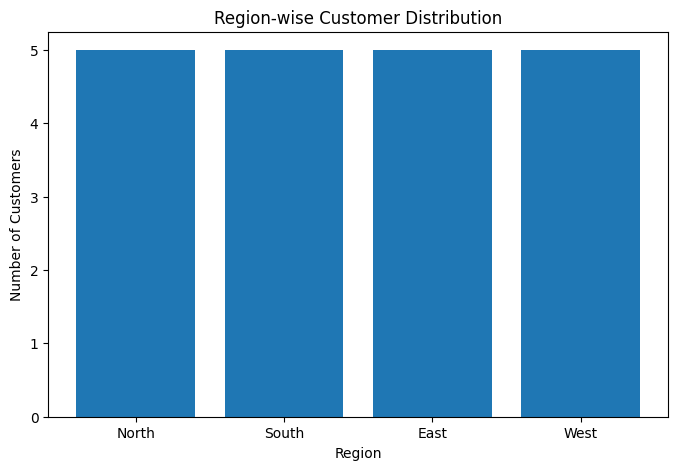

In [34]:
plt.figure(figsize=(8,5))

plt.bar(region_count.index, region_count.values)

plt.title("Region-wise Customer Distribution")
plt.xlabel("Region")
plt.ylabel("Number of Customers")

plt.show()

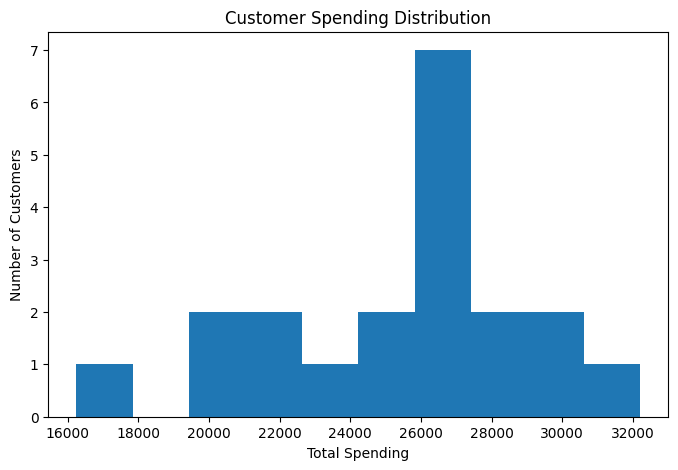

In [35]:
plt.figure(figsize=(8,5))

plt.hist(clean_df["Total_Spend"], bins=10)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.show()

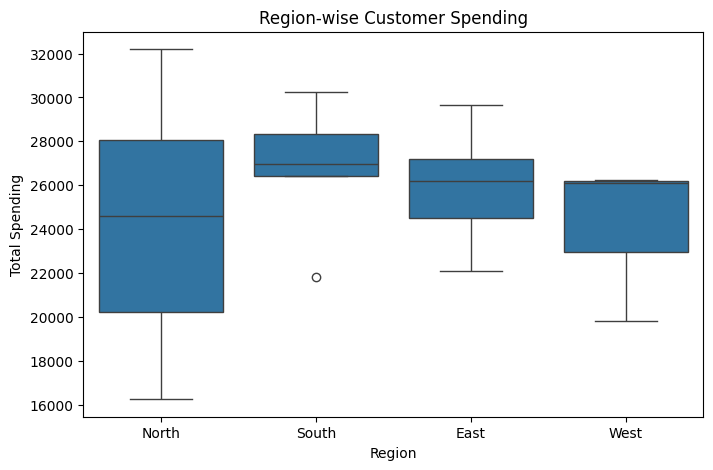

In [36]:
plt.figure(figsize=(8,5))

sns.boxplot(data=clean_df, x="Region", y="Total_Spend")

plt.title("Region-wise Customer Spending")
plt.xlabel("Region")
plt.ylabel("Total Spending")

plt.show()

In [37]:
avg_spending = clean_df.groupby("Region")["Total_Spend"].mean()

print(avg_spending)

Region
East     25921.0
North    24268.0
South    26764.0
West     24257.0
Name: Total_Spend, dtype: float64


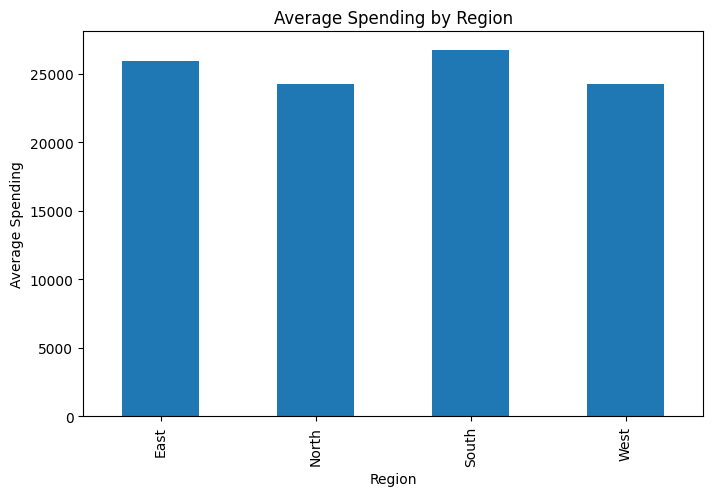

In [38]:
avg_spending.plot(kind="bar", figsize=(8,5))

plt.title("Average Spending by Region")
plt.xlabel("Region")
plt.ylabel("Average Spending")

plt.show()

In [39]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["Region"],
    dtype=int
)

encoded_df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Profession,Work_Experience,Family_Size,Last_Purchase_Date,Total_Spend,Region_East,Region_North,Region_South,Region_West
0,1001,Female,23.0,25000.0,65.0,Student,0,3,2026-01-01,16250.0,0,1,0,0
1,1002,Male,35.0,52000.0,42.0,Engineer,8,4,2026-01-02,21840.0,0,0,1,0
2,1003,Female,29.0,38000.0,78.0,Doctor,5,2,2026-01-03,29640.0,1,0,0,0
3,1004,Male,42.0,75000.0,35.0,Teacher,15,5,2026-01-04,26250.0,0,0,0,1
4,1005,Female,31.0,46000.0,70.0,Artist,4,3,2026-01-05,32200.0,0,1,0,0


In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

encoded_df["Total_Spend_Scaled"] = scaler.fit_transform(
    encoded_df[["Total_Spend"]]
)

encoded_df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Profession,Work_Experience,Family_Size,Last_Purchase_Date,Total_Spend,Region_East,Region_North,Region_South,Region_West,Total_Spend_Scaled
0,1001,Female,23.0,25000.0,65.0,Student,0,3,2026-01-01,16250.0,0,1,0,0,-2.397567
1,1002,Male,35.0,52000.0,42.0,Engineer,8,4,2026-01-02,21840.0,0,0,1,0,-0.917048
2,1003,Female,29.0,38000.0,78.0,Doctor,5,2,2026-01-03,29640.0,1,0,0,0,1.148793
3,1004,Male,42.0,75000.0,35.0,Teacher,15,5,2026-01-04,26250.0,0,0,0,1,0.250947
4,1005,Female,31.0,46000.0,70.0,Artist,4,3,2026-01-05,32200.0,0,1,0,0,1.826813


In [41]:
encoded_df.to_csv(
    "prepared_customer_data.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [42]:
print("Final Shape:", encoded_df.shape)

print("Missing Values:", encoded_df.isnull().sum().sum())

print("Duplicates:", encoded_df.duplicated().sum())

Final Shape: (20, 15)
Missing Values: 3
Duplicates: 0
